# Color Image Processing Lab

All of the programming assignments are to be done in Python using additional libraries specified in the assignments. There are many libraries available, some of which we will be using, and you are welcome to use them with one exception: if the library or a function within it performs the specific function you are asked to code, you may not use that other than perhaps as a reference to compare against. All of the code you submit must be your own. You are welcome to turn in a completed jupyter notebook.


## Pre-lab Notes

Since it is our first time working with color images, we need to be careful of a couple of things. Most RGB color images store each RGB value as an 8-bit number. This is fine for displaying images as shown below:


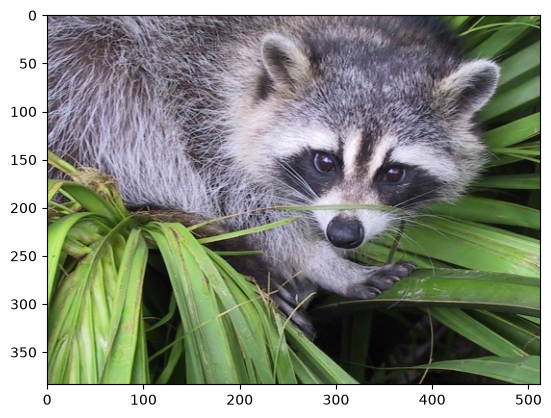

In [19]:
import matplotlib.pyplot as plt
import numpy as np

racoon = plt.imread('racoon.jpg')
plt.imshow(racoon); plt.show()

This is fine for displaying, but becomes a problem once we try to do any image manipulations. We have to beware of overflow. For example, lets say we just want to add 20 to all of the RGB values.


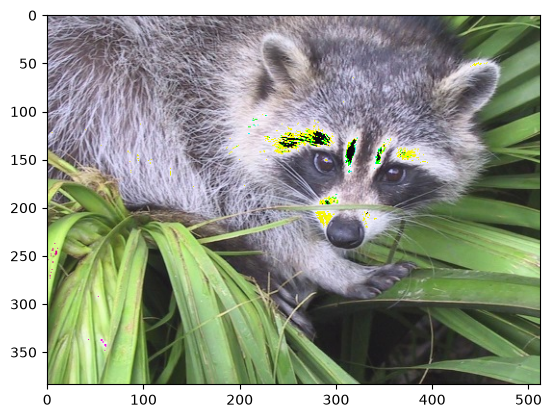

In [20]:
plt.imshow(racoon + 20)
plt.show()

Notice what happens near the white areas of the image. We only had 8-bits to respresent each RGB value (0 to 255). White areas will have values near 255. So when we add 20, the colors go crazy because values have overflowed (ex. 240 + 20 = 4).

You maybe tempted to try something like this:


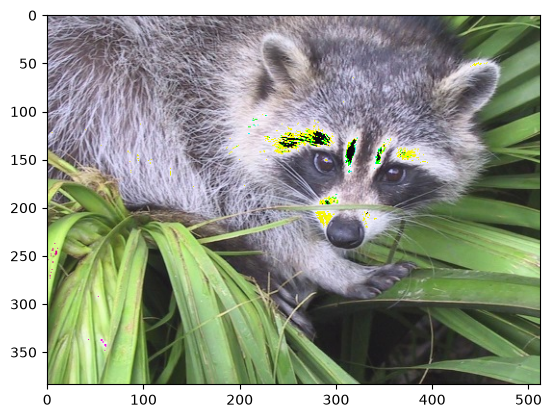

In [21]:
plt.imshow(np.clip(racoon + 20,0,255))
plt.show()

Notice that this still doesn't work because the overflow occurs before the maximum check.

The way to beat this problem is to convert the image into a higher bit representation, do the manipulations, then convert it back down to the 8-bit representation.


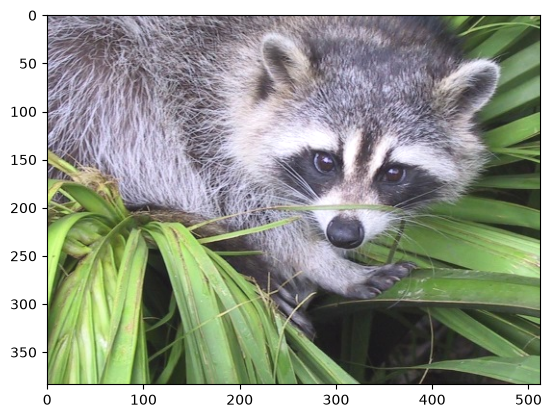

In [22]:
racoon_32 = np.array(racoon, dtype=np.int32)
racoon_32 = np.clip(racoon_32 + 20, 0, 255)
racoon_8 = np.array(racoon_32, dtype=np.uint8)

plt.imshow(racoon_8)
plt.show()

For convenience, we will leave all data in int32 representation. Then, we will simply define a function that converts the image back to 8-bit representation before plotting.


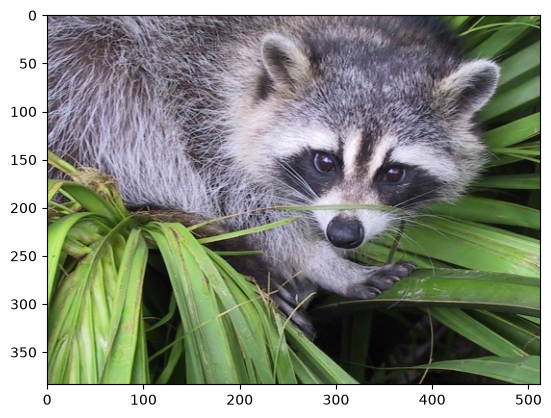

In [23]:
def plotImage(image, title=""):
    im = np.array(image, dtype=np.uint8)
    plt.imshow(im, vmin = 0, vmax = 255)
    plt.title(title)
    plt.show()

racoon = plt.imread('racoon.jpg')
racoon = np.array(racoon, dtype=np.int32)
plotImage(racoon)

You are welcome to use the function above for plotting your own color images.

In this lab, you will also need to be able to convert between RGB values and HSB values. We have provided function that allow you to easily go back and forth while staying in the 0-255 representation for images. You are welcome to use the functions below in this lab.


In [24]:
def toHSB(image):
    from matplotlib import colors
    temp = np.copy(image)
    temp = 255*colors.rgb_to_hsv(temp/255.0)
    return temp.astype(np.int32)
    
def toRGB(image):
    from matplotlib import colors
    temp = np.copy(image)
    temp = 255*colors.hsv_to_rgb(temp/255.0)
    return temp.astype(np.int32)

Now that you have that understanding, you are ready to start the lab.

Implement each of the following functions. Use the provided test cases to test your functions. If you understand the NumPy well, you should be able to implement each of these functions with a single line of code!


## Function 1: Convert to grayscale - Variation 1 (10 pts)

There are two ways to convert an image to grayscale. This function takes in a color image and returns a grayscale image using the following formula:

Gray = 0.299 Red + 0.587 Green + 0.114 Blue


In [25]:
#for every row, for every column, take only the first 3 entries along the last axis" — i.e., grab R, G, B and drop alpha if it exists.
def toGrayScaleV1(image):
    return np.dot(image[...,:3], [0.299, 0.587, 0.114]).astype(np.int32)


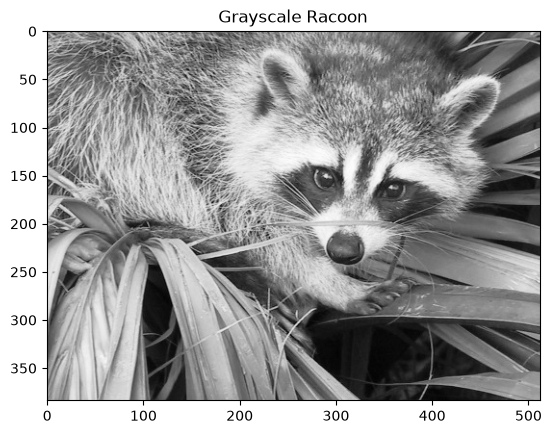

In [26]:
# Test Case
gray_racoon = toGrayScaleV1(racoon)
plt.imshow(gray_racoon,cmap="Greys_r",vmin=0,vmax=255)
plt.title("Grayscale Racoon")
plt.show()

## Function 2: Convert to grayscale - Variation 2 (10 pts)

There are two ways to convert an image to grayscale. This function takes in a color image and returns a grayscale image by converting the image to HSB and setting its saturation value to zero.


In [ ]:
#still takes all pixels and for each set the saturation channel with index 1 from HSB to 0
def toGrayScaleV2(image):
    im = toHSB(image)
    im[..., 1] = 0 
    return toRGB(im)


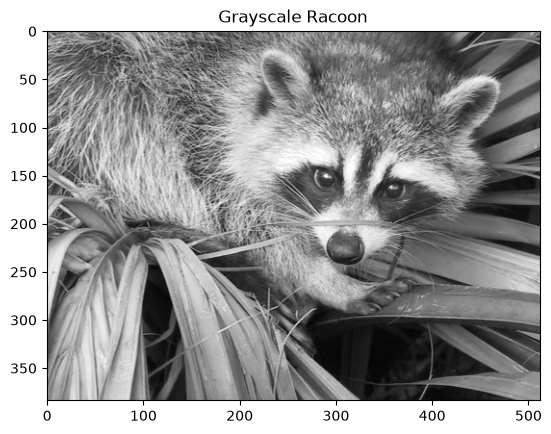

In [28]:
# Test Case
gray_racoon = toGrayScaleV2(racoon)
plt.imshow(gray_racoon,cmap="Greys_r",vmin=0,vmax=255)
plt.title("Grayscale Racoon")
plt.show()

## Function 3: Brightness Adjustment (10 pts)

Takes in a color image and returns the brightened version of that image according to a passed in parameter. Use a max image value of 255.


In [29]:
#still takes all pixels and for each set the brightness channel with index 2 to its value = constant. and then cip in range 0 and 255
#if usx rgb i could have gone to 32bits first to avoid the yellow overflow color
def brightAdjust(image,c):
    im = toHSB(image)
    im[...,2]= np.clip(im[...,2]+c, 0, 255)
    return toRGB(im)



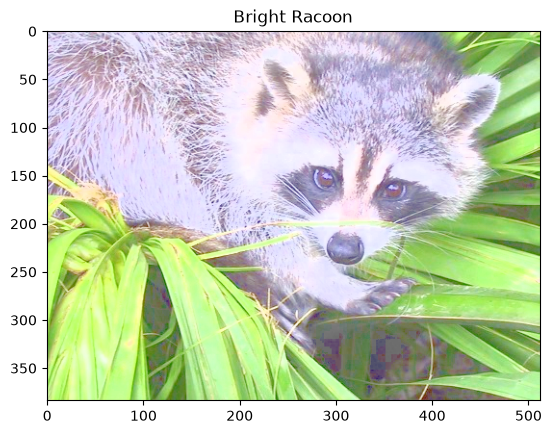

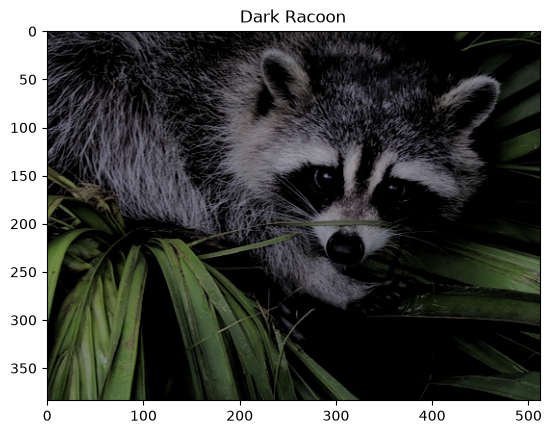

In [30]:
# Test Case
bright_racoon = brightAdjust(racoon,100)
plotImage(bright_racoon, "Bright Racoon")
dark_racoon = brightAdjust(racoon,-100)
plotImage(dark_racoon, "Dark Racoon")

## Function 4: Contrast Adjustment (10 pts)

Takes in a color image and returns the contrasted version of that image according to a passed in parameter. Use a max image value of 255.

Also, rather than a straight linear operation, we will use a mapping similar to what Photoshop does. In particular, the contrast will be in the range [-100,100] where 0 denotes no change, -100 denotes complete loss of contrast, and 100 denotes maximum enhancement (8x multiplier). If _c_ is the contrast parameter, then the level operation applied is:

$$s = \left(\frac{c+100}{100}\right)^4 (r-128) + 128$$

Make sure you work in floating point, not integers. Integer division would not be very acurate.


In [31]:
#similar to previous ie same brightness channel but different contrast formula
def contrastAdjust(image, c):
    im = toHSB(image)
    im[...,2]= np.clip(((c + 100) / 100) ** 4 * (im[...,2].astype(np.float64) - 128) + 128, 0, 255)
    return toRGB(im)


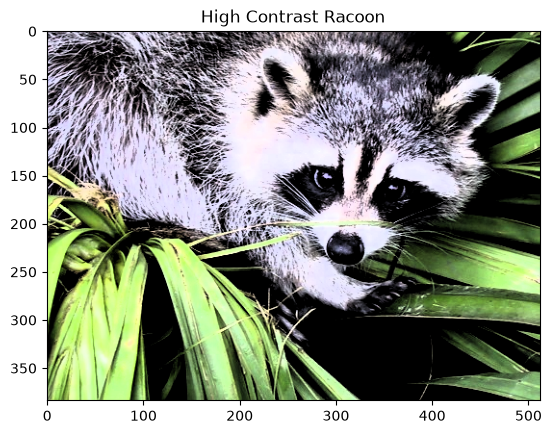

In [32]:
contrast_racoon = contrastAdjust(racoon,30)
plotImage(contrast_racoon, "High Contrast Racoon")

## Function 5: Image Blending (10 pts)

Takes in 2 color images of the same size. Given an alpha value it returns the blended image according to the alpha value. Note that your alpha value can be a single number or a mask image of the same size. The alpha values will be between 0 and 1.

**Note**: If you correctly understand the ideas of broadcasting in Numpy, you can still write this function in a single line!


In [33]:
# Alpha blending = weighted average of the two images: alpha*image1 + (1-alpha)*image2. Cast to float64 first so the multiply/add doesn't overflow or lose precision onalpha can be a scalar or a full-size mask array of the same shape as the images handled by the broadcast here
# (1-alpha) ensures the two weights always sum to 1, so brightness is preserved
def alphaBlend(image1, image2, alpha = .5):
     return (alpha * image1.astype(np.float64) + (1 - alpha) * image2.astype(np.float64)).astype(np.int32)



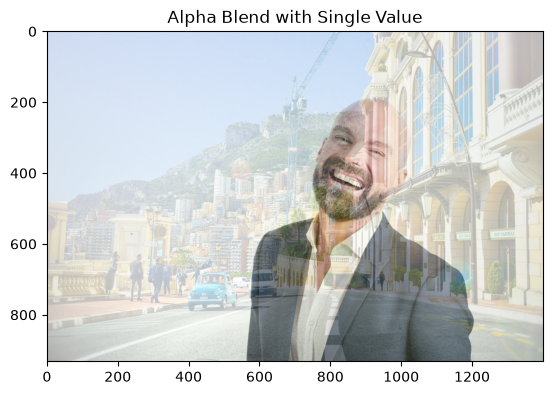

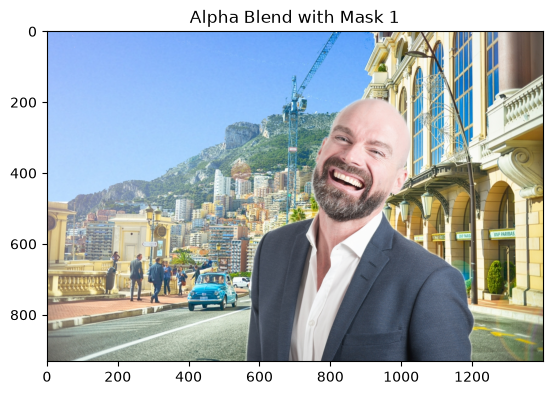

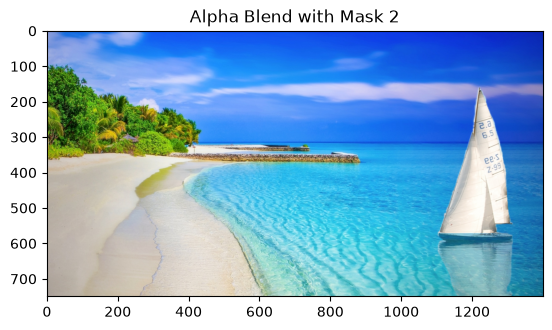

In [34]:
# Test Cases
man = plt.imread("man.jpg")
city = plt.imread("city.jpg")
blended = alphaBlend(man, city, .7)
plotImage(blended, "Alpha Blend with Single Value")

mask1 = plt.imread("alphamask1.jpg")/255.0
blended1 = alphaBlend(man, city, mask1)
plotImage(blended1, "Alpha Blend with Mask 1")

beach = plt.imread("beach.jpg")
boat = plt.imread("boat.jpg")
mask2 = plt.imread("alphamask2.jpg")/255.0
blended2 = alphaBlend(boat, beach, mask2)
plotImage(blended2, "Alpha Blend with Mask 2")